# CP2 analysis notebook

A place to **look at** results. Every figure comes from `plots.py`, the same code that makes the
README's figures, so the two never disagree. The notebook gains a section with each stage.

**Run it top to bottom.** It trains nothing from scratch: model predictions come from the cache
that `python validity.py` fills. If the cache is empty, the scorecard cell computes what's
missing, which takes about 4 minutes once.

Only dev labels are used here. The lockbox stays sealed (see the README, "Stage 1").

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd

import features
import plots
import validity

grids, dev = validity.load_dev()   # all 500k grids; lockbox labels come back as NaN
print(f"{len(grids):,} grids; dev labels per advisor:",
      dict(zip(validity.ADVISORS, (~np.isnan(dev)).sum(0))))

500,000 grids; dev labels per advisor: {'Wellness': np.int64(4000), 'Tax': np.int64(4000), 'Transportation': np.int64(4000), 'Business': np.int64(4000)}


---
## Stage 1 · What the models see

A model reads numbers, not pictures. Here is one city, plus a sample of the 75 engineered
features computed from it. **Change `i`** to explore other cities. The black bars mark what one
feature counts: Park–Residential side-by-side pairs.

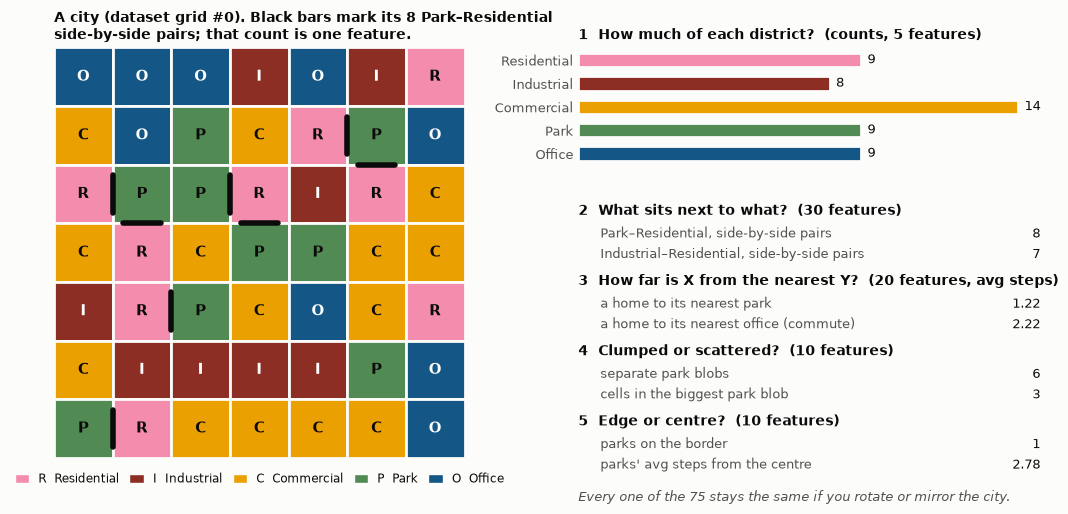

In [2]:
i = 0   # any number from 0 to 499,999
plots.fig_grid_features(grids[i]);

All 75 numbers for the same city, grouped by the question each one answers:

In [3]:
values = features.engineered(grids[i:i + 1])[0]
question = {col: q for q, cols in features.FEATURE_GROUPS.items() for col in cols}
table = pd.DataFrame({
    "question": [question[c] for c in range(len(values))],
    "feature": features.ENGINEERED_NAMES,
    "value": np.round(values, 2),
})
pd.set_option("display.max_rows", 80)
table

,question,feature,value
0,counts,count Residential,9.00
1,counts,count Industrial,8.00
2,counts,count Commercial,14.00
3,counts,count Park,9.00
4,counts,count Office,9.00
5,adjacency,side-by-side Residential-Residential,1.00
6,adjacency,diagonal Residential-Residential,3.00
7,adjacency,side-by-side Residential-Industrial,7.00
8,adjacency,diagonal Residential-Industrial,5.00
9,adjacency,side-by-side Residential-Commercial,11.00


---
## Stage 1 · How the labels are split

Each advisor's 5,000 labels: the **lockbox** (1,000) is opened once at the very end. **Dev**
(4,000) is where every comparison happens, using 5-fold cross-validation repeated 3 times.

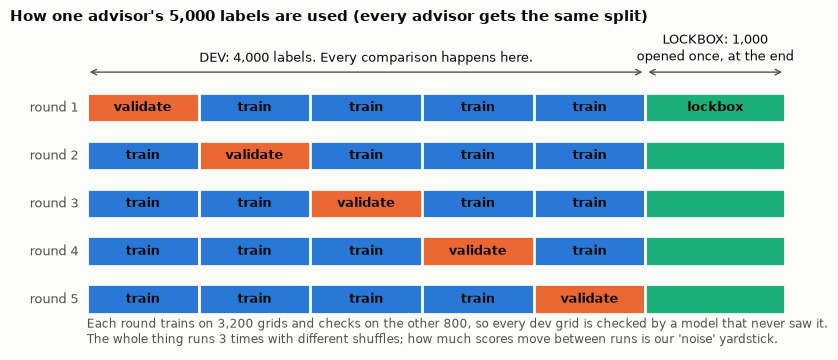

In [4]:
plots.fig_splits();

---
## Stage 1 · The scorecard

**Approved at 98%** is the number we choose models by. Walk down the dev grids from the model's
most confident "pass" to its least. Keep approving while at least 98% of everything approved so
far *truly* scores ≥ 0.75. The count you reach is how many grids the model can vouch for at that
confidence.

- More is better: it's the room we'll have to choose 100 *different* grids later.
- The 98% protects the score, since every grid that fails costs about 1% of it.
- R² (overall accuracy) is shown too, but only as a sanity check.

In [5]:
results = validity.scorecard(verbose=False)   # cached: seconds
validity.print_scorecard(results)


Approved at 98%: dev grids approved while ≥98% truly score ≥ 0.75 (of ~4,000)
  variant                   Wellness             Tax  Transportation        Business
  ridge_onehot             67 ( 7%)      611 (63%)        0 ( 0%)       40 ( 4%)
  gbm_onehot               76 ( 7%)      543 (56%)        5 ( 1%)       82 ( 8%)
  ridge_engineered        242 (24%)      817 (84%)       19 ( 2%)      182 (18%)
  gbm_engineered          534 (52%)      828 (86%)      744 (74%)      836 (84%)
  (in brackets: the share of all truly-passing dev grids those approvals catch)

R² (1.0 = perfect) ± how much it moves fold to fold (the noise yardstick)
  variant                   Wellness             Tax  Transportation        Business
  ridge_onehot           0.481 ±0.027     0.757 ±0.024     0.121 ±0.029     0.481 ±0.036
  gbm_onehot             0.502 ±0.025     0.704 ±0.015     0.293 ±0.026     0.495 ±0.026
  ridge_engineered       0.695 ±0.024     0.871 ±0.016     0.650 ±0.020     0.603 ±0.022
  gbm

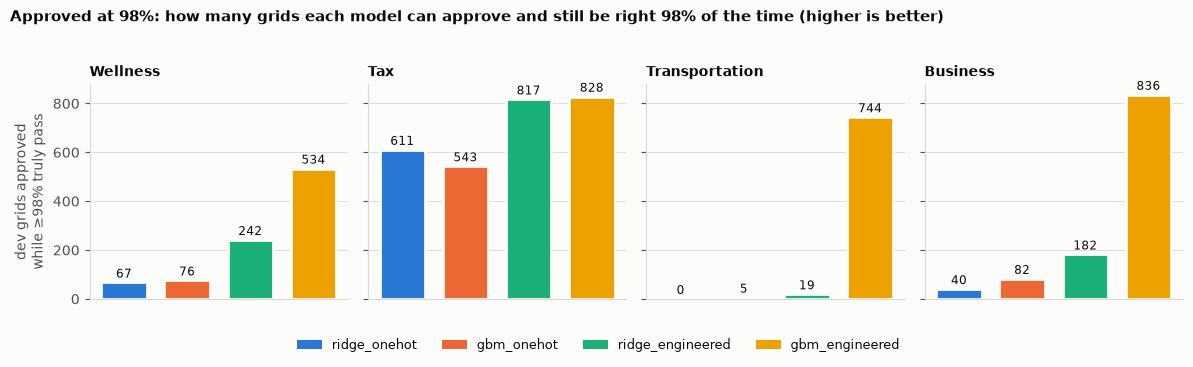

In [6]:
plots.fig_scorecard(results);

---
## Stage 1 · Where a model is right and wrong

Every dot is one dev grid, scored by a model that never saw it.
- **x** = the advisor's true score; **y** = the model's prediction; the dashed line is perfect.
- **Shaded = the costly corner:** the model says "pass" (≥ 0.75) but the advisor says "fail".
  Those are the mistakes that sink a submission.

First the main model, then the starter-notebook-style model for contrast. Look at
Transportation.

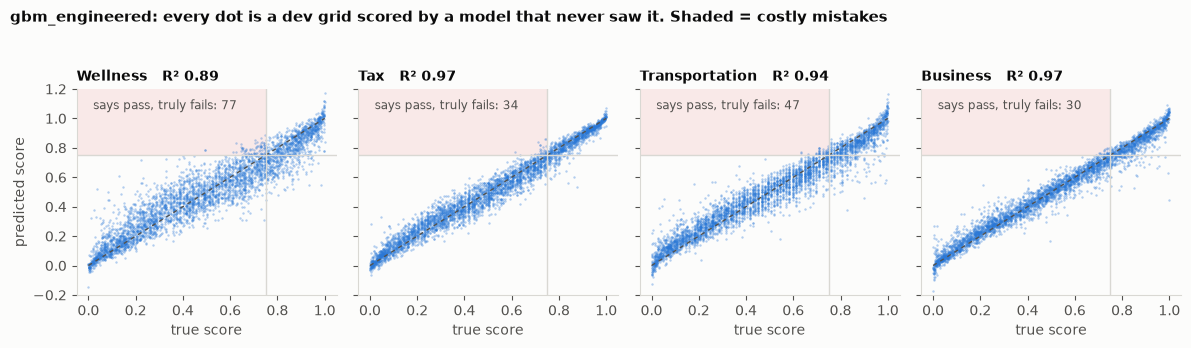

In [7]:
plots.fig_pred_vs_actual(results, "gbm_engineered");

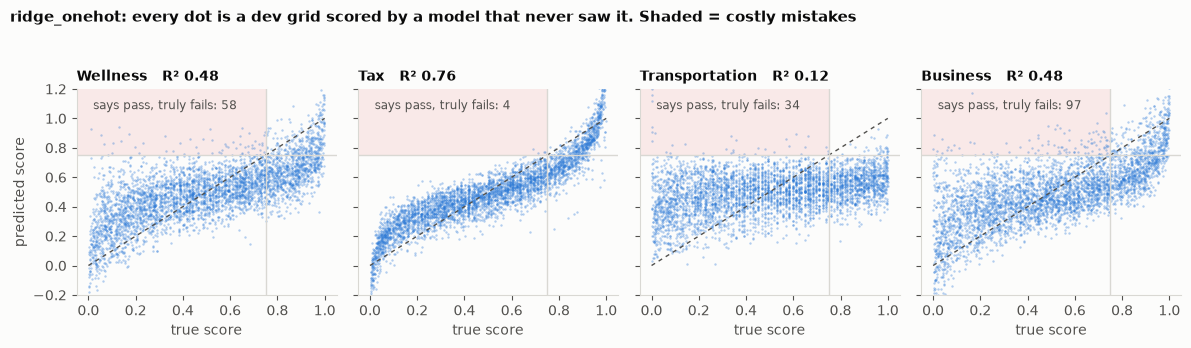

In [8]:
plots.fig_pred_vs_actual(results, "ridge_onehot");

**Things to try**
- Change `i` in the first Stage 1 cell and see how the feature values move.
- In the last cell, swap in `"gbm_onehot"`: same model type as the main model, but given raw
  cells instead of engineered features. Compare Transportation.